In [34]:
import pandas as pd
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import splu

### Grid Configuration

In [35]:
# Grid configuration

domain_w = 2.0  # domain width in meters   
domain_l = 1.0  # domain length in meters 
quartz_w = 0.01 # quartz width in meters
quartz_l = 0.01 # quartz length in meters
depth = 0.01 # depth of domain in meters

Nx_coarse = 500 # target columns in coarse grid
Ny_coarse = 250 # target rows in coarse grid
Nx_quartz = 10 # target columns of Quartz cells
Ny_quartz = 10 # target rows of Quartz cells
Nx_wall = 1 # the fine-grid Aluminum wall is 1-cell thick in x
Ny_wall = 1 # the fine-grid Aluminum wall is 1-cell thick in y


# make sure coarse and fine grid line up
while True:

    # fine grid cell sizes
    dx_fine = quartz_w / Nx_quartz
    dy_fine = quartz_l / Ny_quartz

    # fine grid columns and rows include Aluminum walls 
    # include the top and bottom rows and left and right columns
    Nx_fine = Nx_quartz + 2 * Nx_wall 
    Ny_fine = Ny_quartz + 2 * Ny_wall   

    # coarse grid cell sizes
    dx_coarse = domain_w / Nx_coarse
    dy_coarse = domain_l / Ny_coarse

    # refinement ratios coarse to fine
    m_x = dx_coarse / dx_fine   
    m_y = dy_coarse / dy_fine   

    # do the grid lines for the coarse and fine grid line up?
    if Nx_fine % m_x == 0:
        if Ny_fine % m_y == 0:
            break # the grids line up, so stop loop
            
    # if they don't align, increment quartz rows and columns to alter dx_fine and try again
    Nx_quartz += 1
    Ny_quartz += 1


# how many coarse columns and rows are swapped out by the fine grid
coarse_replaced_x = int(Nx_fine / m_x)
coarse_replaced_y = int(Ny_fine / m_y)


print(f"Quartz resolution: {Nx_quartz} x {Ny_quartz} fine cells")
print(f"Fine grid system (Aluminum walls included): {Nx_fine} x {Ny_fine} cells")
print(f"Coarse grid system: {Nx_coarse} x {Ny_coarse} cells")
print(f"Entire fine system replaces {coarse_replaced_x} x {coarse_replaced_y} coarse cells.")
print(f"Coarse cell size: {dx_coarse}m x {dy_coarse}m")
print(f"Fine cell size: {dx_fine}m x {dy_fine}m")

Quartz resolution: 10 x 10 fine cells
Fine grid system (Aluminum walls included): 12 x 12 cells
Coarse grid system: 500 x 250 cells
Entire fine system replaces 3 x 3 coarse cells.
Coarse cell size: 0.004m x 0.004m
Fine cell size: 0.001m x 0.001m


In [36]:
# Finding fine grid system coordinates in coarse grid system

quartz_center_x = 1.0  # center position from the left wall in meters
quartz_center_y = 0.5  # center position from the top wall in meters

# find the top-left coordinate of the Quartz block in physical space
quartz_top_left_x = quartz_center_x - (quartz_w / 2.0)
quartz_top_left_y = quartz_center_y - (quartz_l / 2.0)

# convert the physical top-left quartz location into coarse grid indices
quartz_start_i = int(np.floor(quartz_top_left_x / dx_coarse))
quartz_start_j = int(np.floor(quartz_top_left_y / dy_coarse))

# including the 1-cell Aluminum wall to find start of fine grid in coarse grid indices 
fine_start_i = int(np.floor(((quartz_top_left_x - dx_fine) / dx_coarse)))
fine_start_j = int(np.floor(((quartz_top_left_y - dy_fine) / dy_coarse)))

# including the 1-cell Aluminum wall to find end of fine grid in coarse grid indices 
fine_end_i = fine_start_i + coarse_replaced_x - 1
fine_end_j = fine_start_j + coarse_replaced_y - 1

print(f"Quartz physical top-left location: ({quartz_top_left_x}m, {quartz_top_left_y}m)")
print(f"Fine grid start: Column {fine_start_i}, Row {fine_start_j}")
print(f"Fine grid end: Column {fine_end_i}, Row {fine_end_j}")

Quartz physical top-left location: (0.995m, 0.495m)
Fine grid start: Column 248, Row 123
Fine grid end: Column 250, Row 125


### Defining Lookup Table

In [37]:
# Defining master lookup table

rows = []

total_coarse = Nx_coarse * Ny_coarse
dirs = (("N", 0, -1), ("E", 1, 0), ("S", 0, 1), ("W", -1, 0))

for j in range(Ny_coarse):
    for i in range(Nx_coarse):
        
        # global index for temperature vector
        k = i + j * Nx_coarse
        
        # North, South, East, and West cell indices
        # if calculated cell index is outside of the grid system it is defined as None
        n_idx = i + (j - 1) * Nx_coarse if j > 0 else None
        s_idx = i + (j + 1) * Nx_coarse if j < Ny_coarse - 1 else None
        e_idx = (i + 1) + j * Nx_coarse if i < Nx_coarse - 1 else None
        w_idx = (i - 1) + j * Nx_coarse if i > 0 else None
        
        # boundary conditions 
        is_neumann_N   = (j == 0)                 # top edge
        is_dirichlet_S = (j == Ny_coarse - 1)     # bottom edge
        is_neumann_W   = (i == 0)                 # left edge
        is_neumann_E   = (i == Nx_coarse - 1)     # right edge 
        
        # check if this coarse cell is inside the fine grid region
        is_in_fine = (fine_start_i <= i <= fine_end_i) and (fine_start_j <= j <= fine_end_j)

        # Use lists because a fine-grid corner cell can have two boundary directions.
        grid_bndry, bndry_neumann, bndry_dirichlet, = [], [], []
        for d, di, dj in dirs:
            ni, nj = i + di, j + dj
            # the neighbour is outside the fine grid
            if (fine_start_i <= ni <= fine_end_i) and (fine_start_j <= nj <= fine_end_j):
                grid_bndry.append(d) 
            # neighbour is top edge, left edge, or right edge -> meaning Neumann boundary 
            elif nj < 0 or ni < 0 or ni > (Nx_coarse-1):
                bndry_neumann.append(d)
            # neighbour is bottom edge -> meaning Dirichlet boundary
            elif nj > (Ny_coarse-1):
                bndry_dirichlet.append(d)


        rows.append({
            "temp_index": k, 
            "grid_resolution": "coarse", 
            "material": "Al",
            "spatial_i": int(i), 
            "spatial_j": int(j),
            # neighbour indices (global index for temperature vector)
            "neighbour_N": int(n_idx) if n_idx is not None else None,
            "neighbour_E": int(e_idx) if e_idx is not None else None,
            "neighbour_S": int(s_idx) if s_idx is not None else None,
            "neighbour_W": int(w_idx) if w_idx is not None else None,
            # boundary bools
            "bndry_dirichlet": bndry_dirichlet,
            "bndry_neumann": bndry_neumann,
            "bndry_material": False,
            "grid_bndry": grid_bndry,
            "in_fine": is_in_fine
        })


for j_q in range(Ny_fine):
    for i_q in range(Nx_fine):
        # global index for temperature vector (after all the coarse grid indices)
        k = total_coarse + (i_q + j_q * Nx_fine)
        
        # check to see if cell is the wall and hence Aluminum
        is_wall = (i_q == 0 or i_q == Nx_fine - 1 or j_q == 0 or j_q == Ny_fine - 1)
        material = "Al" if is_wall else "SiO2"

        # find mirror indices for wall cells
        k_x_mirror, k_y_mirror = None, None
        if is_wall:
           center_x = (m_x - 1)/2 
           center_y = (m_y - 1)/2
           l_x = (i_q % m_y) - center_x
           l_y = (j_q % m_x) - center_y
           i_mirror = i_q - 2 * l_x
           j_mirror = j_q - 2 * l_y
           k_x_mirror = total_coarse + (i_mirror + j_q * Nx_fine)
           k_y_mirror = total_coarse + (i_q + j_mirror * Nx_fine)
        
        # North, South, East, and West cell indices
        # if calculated cell index is outside of the grid system it is defined as None
        n_idx = total_coarse + i_q + (j_q - 1) * Nx_fine if j_q > 0 else None
        s_idx = total_coarse + i_q + (j_q + 1) * Nx_fine if j_q < Ny_fine - 1 else None
        e_idx = total_coarse + (i_q + 1) + j_q * Nx_fine if i_q < Nx_fine - 1 else None
        w_idx = total_coarse + (i_q - 1) + j_q * Nx_fine if i_q > 0 else None

        # Use lists because a fine-grid corner cell can have two boundary directions.
        grid_bndry, mat_bndry = [], []
        for d, di, dj in dirs:
            ni, nj = i_q + di, j_q + dj
            if not (0 <= ni < Nx_fine and 0 <= nj < Ny_fine):
                grid_bndry.append(d)   # the neighbour is outside the fine grid
            else:
                neighbour_is_wall = (ni == 0 or ni == Nx_fine - 1 or nj == 0 or nj == Ny_fine - 1)
                if neighbour_is_wall != is_wall:   # this cell and its neighbour are different materials
                    mat_bndry.append(d)

        rows.append({
            "temp_index": k, 
            "grid_resolution": "fine", 
            "material": material,
            "spatial_i": int(i_q), 
            "spatial_j": int(j_q),
            # neighbour indices (global index for temperature vector)
            "neighbour_N": int(n_idx) if n_idx is not None else None,
            "neighbour_E": int(e_idx) if e_idx is not None else None,
            "neighbour_S": int(s_idx) if s_idx is not None else None,
            "neighbour_W": int(w_idx) if w_idx is not None else None,
            # mirror indices (global index for temperature vector)
            "mirror_x": int(k_x_mirror) if k_x_mirror is not None else None,
            "mirror_y": int(k_y_mirror) if k_y_mirror is not None else None,
            # boundary bools
            "bndry_dirichlet": False,
            "bndry_neumann": False,
            "grid_bndry_direction": grid_bndry,
            "material_bndry_direction": mat_bndry
        })


lookup_df = pd.DataFrame(rows).set_index("temp_index")

In [38]:
# make sure neighbour and mirror indices are Int64 type so that None values are allowed

for direction in ("N", "E", "S", "W"):
    column = f"neighbour_{direction}"
    lookup_df[column] = lookup_df[column].astype("Int64")

for direction in ("x", "y"):
    column = f"mirror_{direction}"
    lookup_df[column] = lookup_df[column].astype("Int64")   

### Grid and Indices Visualization

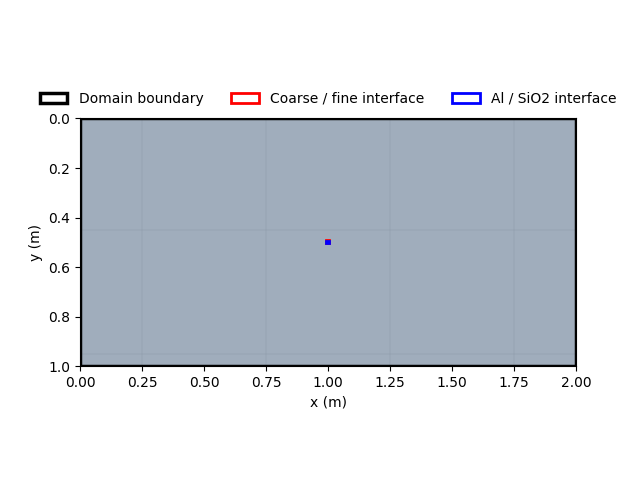

In [50]:
# you need to pip install -U matplotlib ipympl ipywidgets
# zoom in by pressing 'Z', zoom out by pressing 'X'
# produced by AI to make sure grid system is correct

%matplotlib widget
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# draw one filled rectangle with its top-left corner at (x, y); edge/lw give it an optional outline
def DrawRectangle(ax, x, y, dx, dy, colour, edge="none", lw=0, **kw):
    ax.add_patch(Rectangle((x, y), dx, dy, facecolor=colour, edgecolor=edge, linewidth=lw, **kw))

AL, SIO2 = "#c9d6e3", "#f6d6a8"
fx0, fy0 = fine_start_i * dx_coarse, fine_start_j * dy_coarse   # top-left of fine block (m)
fine_w, fine_h = coarse_replaced_x * dx_coarse, coarse_replaced_y * dy_coarse

fig, ax = plt.subplots()

# coarse grid: one Al rectangle for the whole domain, then thin lines to separate the cells
DrawRectangle(ax, 0, 0, domain_w, domain_l, AL)
ax.vlines(np.arange(Nx_coarse + 1) * dx_coarse, 0, domain_l, colors="#8896a5", linewidths=0.3)
ax.hlines(np.arange(Ny_coarse + 1) * dy_coarse, 0, domain_w, colors="#8896a5", linewidths=0.3)

# fine grid: one outlined rectangle per fine cell, coloured by the material stored in lookup_df
for r in lookup_df[lookup_df["grid_resolution"] == "fine"].itertuples():
    DrawRectangle(ax, fx0 + r.spatial_i * dx_fine, fy0 + r.spatial_j * dy_fine, dx_fine, dy_fine,
                  SIO2 if r.material == "SiO2" else AL, edge="#777777", lw=0.4, zorder=2)

# the three borders (outline only, no fill)
for (x, y, w, h), c, lw, name in [
    ((0, 0, domain_w, domain_l), "black", 2.5, "Domain boundary"),
    ((fx0, fy0, fine_w, fine_h), "red", 2, "Coarse / fine interface"),
    ((fx0 + dx_fine, fy0 + dy_fine, Nx_quartz * dx_fine, Ny_quartz * dy_fine), "blue", 2, "Al / SiO2 interface")]:
    ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=c, linewidth=lw, zorder=4, label=name))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)

# "k" global index for temperature vector
texts = []
def label_grid(x0, y0, dx, dy, ni, nj, row_width, index_offset=0, skip=lambda i, j: False):
    xa, xb = sorted(ax.get_xlim())
    ya, yb = sorted(ax.get_ylim())
    box = ax.get_window_extent()
    w_pt = dx * box.width / (xb - xa) * 72 / fig.dpi
    h_pt = dy * box.height / (yb - ya) * 72 / fig.dpi
    fs = min(w_pt / 5, h_pt / 1.5)
    if fs < 4:
        return

    for j in range(max(int((ya - y0) // dy), 0), min(int((yb - y0) // dy), nj - 1) + 1):
        for i in range(max(int((xa - x0) // dx), 0), min(int((xb - x0) // dx), ni - 1) + 1):
            if not skip(i, j):
                temp_index = index_offset + i + j * row_width
                texts.append(ax.text(
                    x0 + (i + .5) * dx, y0 + (j + .5) * dy, str(temp_index),
                    ha="center", va="center", fontsize=fs, zorder=5, clip_on=True
                ))

# redraw the labels whenever the view changes
def update_labels(event=None):
    for t in texts:
        t.remove()
    texts.clear()
    ax.apply_aspect()                                     # make the plot-area size current before measuring
    in_fine = lambda i, j: fine_start_i <= i <= fine_end_i and fine_start_j <= j <= fine_end_j
    label_grid(0, 0, dx_coarse, dy_coarse, Nx_coarse, Ny_coarse,
               row_width=Nx_coarse, skip=in_fine)
    label_grid(fx0, fy0, dx_fine, dy_fine, Nx_fine, Ny_fine,
               row_width=Nx_fine, index_offset=total_coarse)                 


ax.set_aspect("equal")
ax.set_xlim(0, domain_w)
ax.set_ylim(domain_l, 0)                                  # j = 0 is the top row
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")

# optional: start zoomed in on the fine block instead of the whole domain
# ax.set_xlim(fx0 - 0.03, fx0 + fine_w + 0.03); ax.set_ylim(fy0 + fine_h + 0.02, fy0 - 0.02)
def on_key(event):
    if event.key not in ("z", "x"):
        return
    s = 0.6 if event.key == "z" else 1.25                # z shrinks the view (zoom in), x enlarges it (zoom out)
    xa, xb = ax.get_xlim(); ya, yb = ax.get_ylim()
    cx = event.xdata if event.xdata is not None else (xa + xb) / 2   # xdata is None when the cursor is off the plot
    cy = event.ydata if event.ydata is not None else (ya + yb) / 2
    ax.set_xlim(cx - (cx - xa) * s, cx + (xb - cx) * s)
    ax.set_ylim(cy - (cy - ya) * s, cy + (yb - cy) * s)

fig.canvas.mpl_connect("key_press_event", on_key)
ax.callbacks.connect("xlim_changed", update_labels)
ax.callbacks.connect("ylim_changed", update_labels)

update_labels()
plt.show()

### Defining Material and System Variables 

In [40]:
# Defining physical variables of materials and overall system

# Aluminum properties
kappa_0_Al = 0.8 # kappa_Al (thermal conductivity) = kappa_0_Al * u^3, [units: W/m*K^4]
beta_Al = 0.11119 # c_Al (specific heat capacity) = beta_Al * u^3, [units: J/kg*K^4]
rho_Al = 2700 # mass density, [units: kg/m^3]

# Quartz (SiO2) properties (PLACEHOLDERS -> LOOK UP IN POBELL)
kappa_0_Q = 1.38 # kappa_Q (thermal conductivity) = kappa_0_Q * u^3, [units: W/m*K^4]
beta_Q = 0.765 # c_Q (specific heat capacity) = beta_Q * u^3, [units: J/kg*K^4]
rho_Q = 2650 # mass density, [units: kg/m^3]


P_heater = 10.0 # power of heater [units: W]
q_dot = np.zeros(len(lookup_df)) # volumetric heat generation at each element [units: W/m^3]

u_fixed = 0.01 # fixed temperature for Dirichlet boundary condition (bottom wall), = 10mK [units: K]
w_fixed = u_fixed ** 4

# PLACEHOLDER -> CHANGE LATER
C = 1.0/400.0 # R_K (Kapitza resistance between Aluminum and Quartz) = C/A*T^3, [units: m^2*K^4/W] 

### Defining Time Steps

In [41]:
t_total = 750.0 # total simulation time [units]
dt = 0.5 # time step [units: s]
N_t_steps = int(t_total/dt) # number of time steps

### Defining Constants for Matrix-Vector System

In [42]:
# Defining constants that are coefficients in the systems of equations

# volumes of coarse and fine cells
V_coarse = dx_coarse * dy_coarse * depth
V_fine = dx_fine * dx_fine * depth

# storage coeffiecents for cells [units: J/K^4] - energy per unit w
a_P_Al = (rho_Al * beta_Al * V_coarse)/4 # coarse Al
a_P_Al_f = (rho_Al * beta_Al * V_fine)/4 # fine Al
a_P_Q = (rho_Q * beta_Q * V_fine)/4 # coarse quartz

# heat conductance for cells in w-space before being multiplied by the difference in w
def conductance(kappa0, face_len, dist):
    """
    Args:
        kappa0 (float): kappa (thermal conductivity) = kappa_0 * u^3
                        this is based on the material
        face_len (float): length of the face of the cell that the heat is flowing in/out of 
                          this is based on whether the cell is coarse or fine
        dist (float): distance from the center of this cell to the center of the neighbouring cell
                      this is based on whether a grid boundary is present or not

    Returns: 
        heat_conductance (float): heat conductance in w-space before being multiplied by the
                                  difference in w
    """
    face_area = face_len * depth

    # the division of 4 is from the w transform: w = u^4
    heat_conductance = (kappa0 * face_area) / (4 * dist)
    return heat_conductance

# constants for coarse-grid Aluminum cells
# (conductance multiplied by the time step)
a_x_Al = conductance(kappa_0_Al, dy_coarse, dx_coarse) * dt
a_y_Al = conductance(kappa_0_Al, dx_fine, dy_fine) * dt

# constants for fine-grid Alumnium cells
a_x_Al_f = conductance(kappa_0_Al, dy_fine, dx_fine) * dt 
a_y_Al_f = conductance(kappa_0_Al, dx_fine, dy_fine) * dt

# constants for Quartz cells
a_x_Q = conductance(kappa_0_Q, dy_fine, dx_fine) * dt
a_y_Q = conductance(kappa_0_Q, dx_fine, dy_fine) * dt

# constants for grid change (coarse to fine and fine to coarse) at the interface - Aluminum cells
a_x_f_c = conductance(kappa_0_Al, dy_fine, ((dx_coarse)/2 + (dx_fine)/2)) * dt 
a_y_f_c = conductance(kappa_0_Al, dx_fine, ((dy_coarse)/2 + (dy_fine)/2)) * dt 

# constants for material change (Aluminum to Quartz and Quartz to Aluminum) at the interface
# takes into account Kapitza resistance
a_x_Al_Q = (dt * dy_fine * depth)/(((2*dx_fine)/kappa_0_Q)+ 4*C + ((2*dx_fine)/kappa_0_Al))
a_y_Al_Q = (dt * dx_fine * depth)/(((2*dy_fine)/kappa_0_Q)+ 4*C + ((2*dy_fine)/kappa_0_Al))

# volumetric heat generation at top-left coarse-grid cell
# the top-left cell has the heater
q_dot[0] = P_heater / V_coarse

# heat generation at every cell multiplied by time step
gen = q_dot * V_coarse * dt # coarse-grid cell
gen_fine = q_dot * V_fine * dt # fine-grid cell


### Helper Functions for Assembling Matrix-Vector System

In [43]:
# Helper functions
def fine_ids_across_coarse_face(cell, direction):
    """
    Args:
        cell: a coarse-grid cell row from lookup table (lookup_df)
        direction (str): "N", "S", "E", or "W"
    
    Returns:
        fine_ids (list): list of the fine-grid cell global indices along
                         the coarse face
    
    """
    
    # i and j values of cell in coarse-gird system
    i = int(cell.spatial_i)
    j = int(cell.spatial_j)

    mx = int(round(m_x))
    my = int(round(m_y))

    if direction in ("N", "S"):

        # starting i in local fine-grid system         
        start_i = (i - fine_start_i) * mx

        # if direction is North this is the bottom row of the fine-grid system
        # otherwise the direction is South so this is the top row of the fine-grid system
        fine_j = Ny_fine - 1 if direction == "N" else 0

        # global indices of the fine-grid cells along coarse face
        # start from starting i to the end of the coarse face
        fine_ids =  [total_coarse + fine_i + fine_j * Nx_fine
            for fine_i in range(start_i, start_i + mx)]
        
        return fine_ids

    # starting j in local fine-grid system
    start_j = (j - fine_start_j) * my

    # if direction is West this is the right column of the fine-grid system
    # otherwise the direction is East so this is the left column of the fine-grid system
    fine_i = Nx_fine - 1 if direction == "W" else 0

    # global indices of the fine-grid cells along coarse face
    # start from starting j to the end of the coarse face
    fine_ids = [total_coarse + fine_i + fine_j * Nx_fine
            for fine_j in range(start_j, start_j + my)]
    
    return fine_ids


def coarse_neighbour_ids_for_fine_cell(cell):
    """
    Args:
        cell: a coarse-grid cell row from lookup table (lookup_df)

    Returns:
        coarse_neighbours_global (dict): {direction: global index}
                                        for a fine-grid cell's coarse neighbours
    """

    # i and j values of cell in fine-gird system
    i = int(cell.spatial_i)
    j = int(cell.spatial_j)

    mx = int(round(m_x))
    my = int(round(m_y))

    coarse_neighbours = {}

    # At the fine patch's left/right edge, each fine cell meets a coarse cell
    # in the corresponding coarse row.

    # if the cell is in the left column of the fine-grid system
    # the coarse neighbour is to the West
    if i == 0:

        # fine_start_i and fine_start_j is where the fine-grid system starts in
        # coarse-grid system coordinates
        coarse_neighbours["W"] = (fine_start_i - 1, fine_start_j + (j // my))

    # if the cell is in the right column of the fine-grid system
    # the coarse neighbour is to the East
    if i == Nx_fine - 1:
        coarse_neighbours["E"] = (fine_start_i + coarse_replaced_x, fine_start_j + (j // my))

    # if the cell is in the top row of the fine-grid system
    # the coarse neighbour is to the North
    if j == 0:
        coarse_neighbours["N"] = (fine_start_i + (i // mx), fine_start_j - 1)

    # if the cell is in the bottom row of the fine-grid system
    # the coarse neighbour is to the South
    if j == Ny_fine - 1:
        coarse_neighbours["S"] = (fine_start_i + (i // mx), fine_start_j + coarse_replaced_y)

    # convert coarse (i, j) coordinates into global indices
    coarse_neighbours_global = {
        direction: coarse_i + coarse_j * Nx_coarse
        for direction, (coarse_i, coarse_j) in coarse_neighbours.items()
        if 0 <= coarse_i < Nx_coarse and 0 <= coarse_j < Ny_coarse
    }

    return coarse_neighbours_global

### Assembling Initital Matrix-Vector System

In [44]:
# the matrix size is the total number of global indices 
# which is the number of cells we are tracking for temperature
# which is the number of rows in the lookup table
matrix_size = len(lookup_df)

# the matrix has the dimensions matrix_size x matrix_size
# store the matrix as a sparse matrix using lil_matrix to save memory
matrix = lil_matrix((matrix_size, matrix_size))

# initial temperature vector
u_initial = np.full(matrix_size, u_fixed)

# initial w temperature
w_initial = u_initial ** 4

# right hand side vector
b = np.zeros(matrix_size)

# heat generation for the dimensions of fine-grid system 
# currently this is zero but q_dot could be changed
gen_fine = q_dot * dx_fine * dy_fine * dt

# iterate through the rows of the lookup table
# hence iterate through each cell
for cell in lookup_df.itertuples():

    if cell.grid_resolution == "coarse":
        if cell.material == "Al":

            # if the cell is coarse and within the fine-grid system
            # w remains unchanged an doesn't connect to any other cell
            # so this cell is essentially ignored
            if cell.in_fine:
                matrix[cell.Index, cell.Index] = 1.0
                b[cell.Index] = w_initial[cell.Index]

            else:
                neumann_directions = cell.bndry_neumann or []
                dirichlet_directions = cell.bndry_dirichlet or []
                grid_directions = cell.grid_bndry or []

                for direction, axis in (("N", "y"), ("E", "x"), ("S", "y"), ("W", "x")):

                    # global index of cell's neighbour in this direction 
                    raw_neighbour = getattr(cell, f"neighbour_{direction}")

                    # make sure the index is an integer if it's defined
                    neighbour_id = (int(raw_neighbour) if pd.notna(raw_neighbour) else None)

                    interface_coefficient = 0.0
                    dircell_coefficient = 0.0
                    rhs_coefficient = 0.0

                    # if in this direction there is a Neumann boundary no terms or coefficients get added
                    if direction in neumann_directions:
                        pass

                    # if in this direction there is a Dirchlet boundary
                    elif direction in dirichlet_directions:
                        if axis == "x":
                            dircell_coefficient = 2 * a_x_Al
                        elif axis == "y":
                            dircell_coefficient = 2 * a_y_Al
                        rhs_coefficient = dircell_coefficient * w_fixed

                    # if in this direction there is a grid boundary
                    elif direction in grid_directions:
                        if axis == "x":
                            # if moving in direction of x axis, the fine cells along
                            # the coarse face are on the y axis hence m_y
                            connection_count = int(round(m_y))
                            fine_interface = a_x_f_c
                        elif axis == "y":
                            connection_count = int(round(m_x))
                            fine_interface = a_y_f_c

                        # the interface coefficient for the coarse cell is all the
                        # fine interface coeffiecents along the coarse cell's face added up
                        interface_coefficient = connection_count * fine_interface

                        # coefficients for all the fine cells along the coarse cell
                        for fine_id in fine_ids_across_coarse_face(cell, direction):
                            matrix[cell.Index, fine_id] -= fine_interface

                    # no boundary conditions apply and this is an interior coarse-grid Aluminum cell
                    elif neighbour_id is not None:
                        if axis == "x":
                            interface_coefficient = a_x_Al
                        else:
                            interface_coefficient = a_y_Al

                        matrix[cell.Index, neighbour_id] -= interface_coefficient

                    matrix[cell.Index, cell.Index] += (interface_coefficient + dircell_coefficient)
                    b[cell.Index] += rhs_coefficient

                matrix[cell.Index, cell.Index] += a_P_Al
                b[cell.Index] += (a_P_Al * w_initial[cell.Index] + gen[cell.Index])

    elif cell.grid_resolution == "fine":
        grid_directions = cell.grid_bndry_direction or []
        material_directions = cell.material_bndry_direction or []

        # fine-grid Aluminum
        if cell.material == "Al":

            # False if grid_directions is empty
            # True if grid_directions is non-empty
            if grid_directions:
                for direction, axis in (("N", "y"), ("E", "x"), ("S", "y"), ("W", "x")):
                    # global index of cell's neighbour in this direction 
                    raw_neighbour = getattr(cell, f"neighbour_{direction}")
                    
                    # make sure the index is an integer if it's defined
                    # this shouldn't be a problem as the fine grid system isn't bordering any domain boundaries 
                    neighbour_id = (int(raw_neighbour) if pd.notna(raw_neighbour) else None)

                    interface_coefficient = 0.0

                    # mirror coefficient is used for correction at grid boundary 
                    # when the fine and coarse cells aren't alligned. 
                    mirror_coefficient = 0.0

                    # if in this direction there is a grid boundary
                    if direction in grid_directions:

                        # find the coarse neighbours
                        # the helper function returns a dictonary of the directions of the coarse
                        # neighbours and their associated global index
                        coarse_neighbours = coarse_neighbour_ids_for_fine_cell(cell)

                        # get the global index of the cell in this direction from the dictonary
                        neighbour_id = coarse_neighbours.get(direction)

                        if axis == "x":
                            interface_coefficient = a_x_f_c
                            mirror_coefficient = a_y_f_c / 2
                        else:
                            interface_coefficient = a_y_f_c
                            mirror_coefficient = a_x_f_c / 2

                    # if in this direction there is a material boundary
                    elif direction in material_directions:
                        if axis == "x":
                            interface_coefficient = a_x_Al_Q
                        elif axis == "y":
                            interface_coefficient = a_y_Al_Q

                    # no boundary conditions apply and this is an interior fine-grid Aluminum cell
                    elif pd.notna(neighbour_id):
                        if axis == "x":
                            interface_coefficient = a_x_Al_f
                        elif axis == "y":
                            interface_coefficient = a_y_Al_f

                    matrix[cell.Index, cell.Index] += interface_coefficient

                    # attach mirror coefficients to the mirror terms if applicable
                    if mirror_coefficient != 0.0:
                        matrix[cell.Index, cell.Index] += mirror_coefficient
                        axis_opp = "y" if axis == "x" else "x"
                        mirror_id = getattr(cell, f"mirror_{axis_opp}")

                        if pd.notna(mirror_id):
                            matrix[cell.Index, int(mirror_id)] -= mirror_coefficient

                    if pd.notna(neighbour_id):
                        matrix[cell.Index, int(neighbour_id)] -= interface_coefficient

                matrix[cell.Index, cell.Index] += a_P_Al_f
                b[cell.Index] = (a_P_Al_f * w_initial[cell.Index] + gen_fine[cell.Index])

            # if grid_directions is empty and material_directions is non-empty
            # in this case where the fine-grid Alumnium wall is only one cell thick
            # this will never be true 
            elif material_directions:
                for direction, axis in (("N", "y"), ("E", "x"), ("S", "y"), ("W", "x")):
                    neighbour_id = getattr(cell, f"neighbour_{direction}")
                    interface_coefficient = 0.0

                    if direction in material_directions:
                        if axis == "x":
                            interface_coefficient = a_x_Al_Q
                        elif axis =="y":
                            interface_coefficient = a_y_Al_Q

                    elif pd.notna(neighbour_id):
                        if axis == "x":
                            interface_coefficient = a_x_Al_f
                        elif axis == "y":
                            interface_coefficient = a_x_Al_f

                    matrix[cell.Index, cell.Index] += interface_coefficient

                    if pd.notna(neighbour_id):
                        matrix[cell.Index, int(neighbour_id)] -= interface_coefficient

                matrix[cell.Index, cell.Index] += a_P_Al_f
                b[cell.Index] = (a_P_Al_f * w_initial[cell.Index] + gen_fine[cell.Index])

            # both grid_directions and material_directions are empty
            # once again because the fine-grid Alumnium wall is only one cell thick
            # these cells will always border the grid boundary or the grid boundary and the material boundary 
            else:
                for direction, axis in (("N", "y"), ("E", "x"), ("S", "y"), ("W", "x")):
                    neighbour_id = getattr(cell, f"neighbour_{direction}")

                    if pd.notna(neighbour_id):
                        interface_coefficient = a_x_Al_f if axis == "x" else a_x_Al_f
                        matrix[cell.Index, cell.Index] += interface_coefficient
                        matrix[cell.Index, int(neighbour_id)] -= interface_coefficient

                matrix[cell.Index, cell.Index] += a_P_Al_f
                b[cell.Index] = (a_P_Al_f * w_initial[cell.Index] + gen_fine[cell.Index])

        # fine-grid Quartz
        elif cell.material == "SiO2":
            for direction, axis in (("N", "y"), ("E", "x"), ("S", "y"), ("W", "x")):
                neighbour_id = getattr(cell, f"neighbour_{direction}")
                interface_coefficient = 0.0

                if direction in material_directions:
                    if axis == "x":
                        interface_coefficient = a_x_Al_Q
                    elif axis == "y":
                        interface_coefficient = a_y_Al_Q

                elif pd.notna(neighbour_id):
                    if axis == "x":
                        interface_coefficient = a_x_Q
                    elif axis == "y":
                        interface_coefficient = a_y_Q

                matrix[cell.Index, cell.Index] += interface_coefficient

                if pd.notna(neighbour_id):
                    matrix[cell.Index, int(neighbour_id)] -= interface_coefficient

            matrix[cell.Index, cell.Index] += a_P_Q
            b[cell.Index] = (a_P_Q * w_initial[cell.Index] + gen_fine[cell.Index])

### Iterate over Time and Solve Matrix-Vector System

In [45]:
# splu requires CSC (Compressed Sparse Columnn) matrix as input
A = matrix.tocsc()  

# splu(A) computes a sparse LU factorization of A
#    P_r A P_c = L U    (equivalently, A = (P_r)^T L U (P_c)^T)
# where
# L is a lower triangular matrix
# U is an upper triangular matrix
# P_r and P_c are permutation matrices 
# the permutation matrices are orthogonal. Thus, (P_r)^-1 = (P_r)^T and (P_c)^-1 = (P_c)^T
# P_r reorders rows for numerical stability (so we never divide by a tiny pivot, which blows up the multipliers)
# P_c reorders columns to reduce creating new nonzero entries when factoring into L and U
lu = splu(A)

is_coarse = (lookup_df.grid_resolution == "coarse").to_numpy()
in_fine   = (lookup_df.in_fine == True).to_numpy()
is_Q      = (lookup_df.material == "SiO2").to_numpy()

# np array of storage coefficients
# if cell is coarse 
#   -> check if cell is in fine grid system 
#      -> if it is the storage coefficient is set to 1.0
#      -> if it is not the storage coefficient is set to a_P_Al
# if cell is not coarse (cell is fine)
#   -> check if cell is quartz
#      -> if it is the storage coefficient is set to a_P_Q
#.     -> if it is not (cell is Al) the storage coefficient is set to a_P_Al_f
storage = np.where(is_coarse,
                   np.where(in_fine, 1.0, a_P_Al),     
                   np.where(is_Q, a_P_Q, a_P_Al_f))

# generation is already inside b so the static part is just
# b_static is the part of b that remains unchanged over time
b_static = b - storage * w_initial

# temperature matrix
# dimensions: (total number of cells) x (number of time steps)
u = np.full((matrix_size, N_t_steps), u_fixed)

# the current w vector is the initial w vector
w_current = w_initial.copy()

# iterate through time steps
for t in range(1, N_t_steps):

    # update b based on the current w
    b_current = storage * w_current + b_static

    # update w by solving the matrix-vector system
    w_current = lu.solve(b_current)

    # transform w back to u
    # update the temperature matrix at this time step
    u[:, t] = w_current ** 0.25

### Heat Map

frame indices: [50, 150, 300, 600, 1499]  times (s): [25.0, 75.0, 150.0, 300.0, 749.5]
colour range: 0.01 to 11.8 K (log)


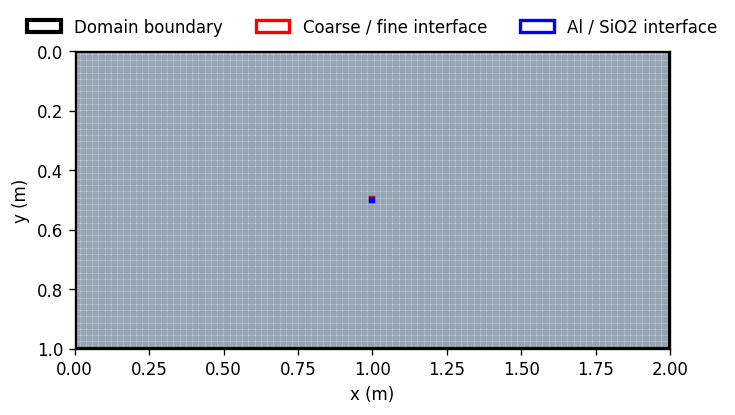

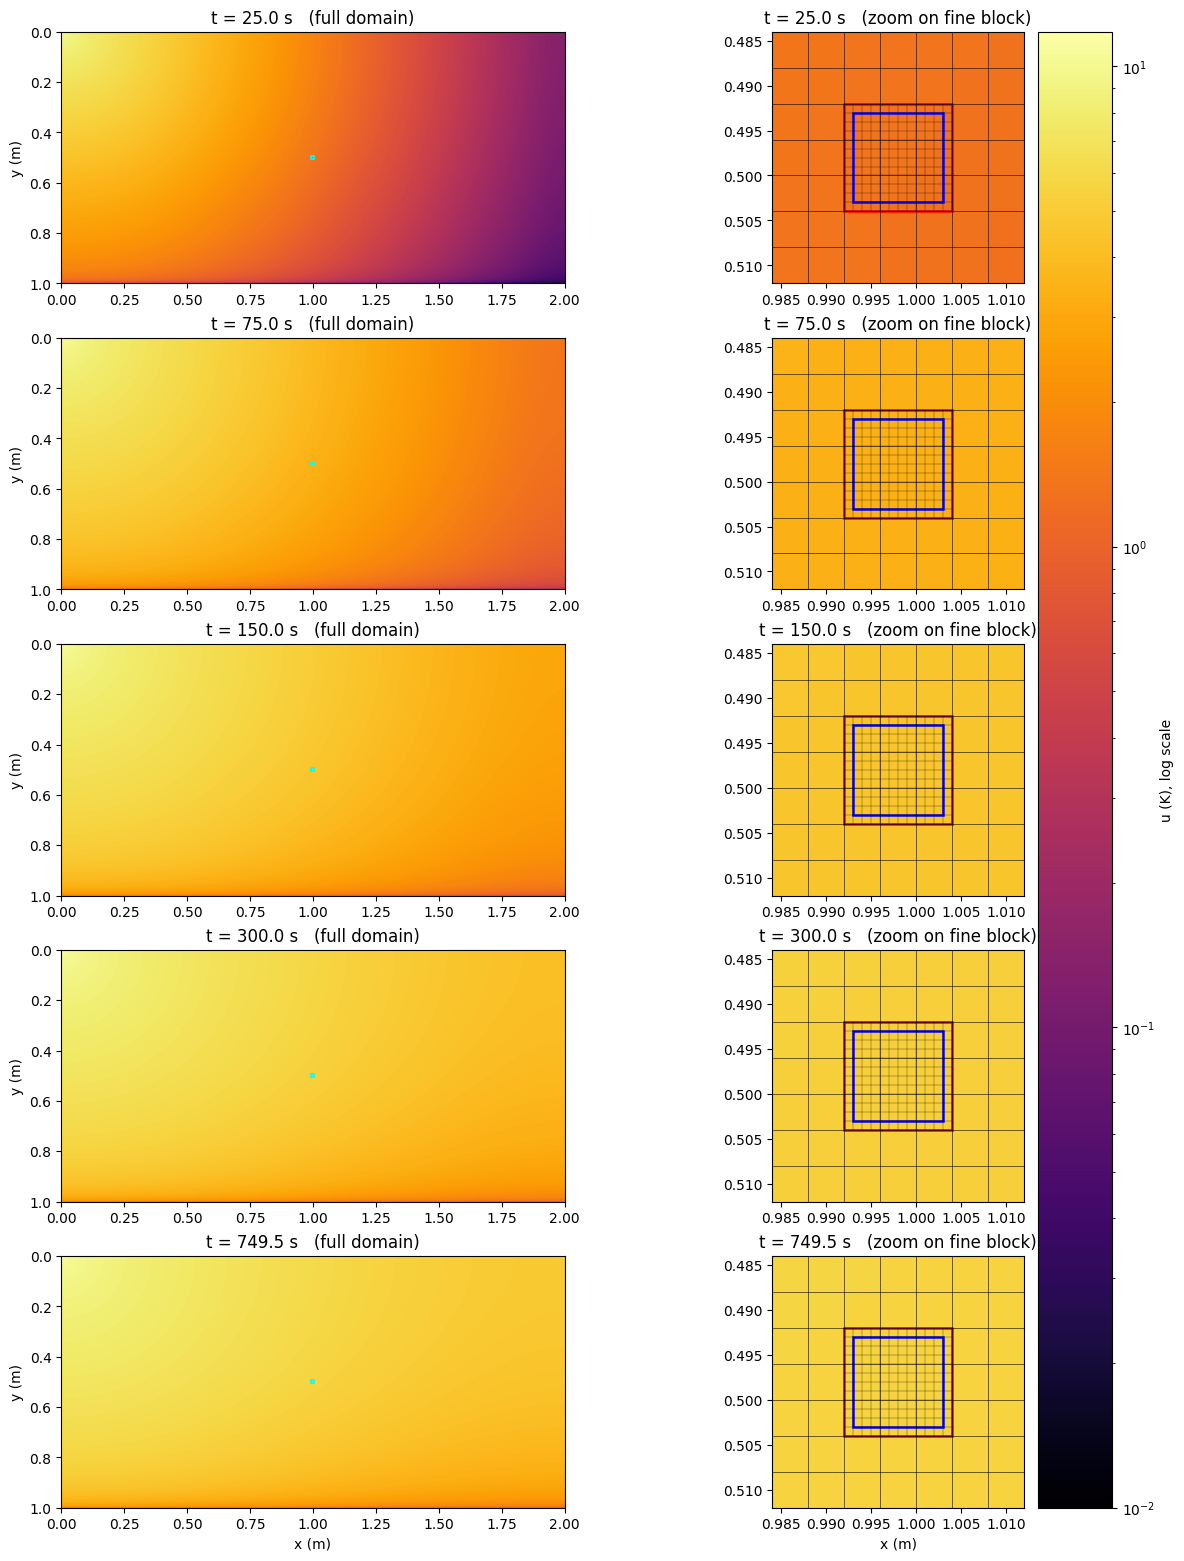

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Rectangle

%matplotlib inline

# ---------- settings ----------
t_want = [25, 75, 150, 300, 750]       # seconds (multiples of dt)
scale  = "log"                         # "log" or "linear"
vmin   = u_fixed                       # lower colour limit (K); override if you like
vmax   = None                          # None -> maximum over the chosen frames

frames   = [min(int(round(t / dt)), N_t_steps - 1) for t in t_want]
t_actual = [f * dt for f in frames]
print("frame indices:", frames, " times (s):", t_actual)

# ---------- geometry ----------
fx0, fy0 = fine_start_i * dx_coarse, fine_start_j * dy_coarse
fine_w, fine_h = coarse_replaced_x * dx_coarse, coarse_replaced_y * dy_coarse
fx1, fy1 = fx0 + fine_w, fy0 + fine_h
qx0, qy0 = fx0 + dx_fine, fy0 + dy_fine
qw, qh = Nx_quartz * dx_fine, Ny_quartz * dy_fine

pad = 2
i0, i1 = max(fine_start_i - pad, 0), min(fine_end_i + pad + 1, Nx_coarse)
j0, j1 = max(fine_start_j - pad, 0), min(fine_end_j + pad + 1, Ny_coarse)
zx = (i0 * dx_coarse, i1 * dx_coarse)
zy = (j1 * dy_coarse, j0 * dy_coarse)

coarse_in_fine = np.zeros((Ny_coarse, Nx_coarse), dtype=bool)
coarse_in_fine[fine_start_j:fine_end_j + 1, fine_start_i:fine_end_i + 1] = True

def fields(f):
    raw_c = u[:total_coarse, f].reshape(Ny_coarse, Nx_coarse)
    raw_f = u[total_coarse:, f].reshape(Ny_fine, Nx_fine)
    uc = np.ma.masked_where(coarse_in_fine | ~np.isfinite(raw_c), raw_c)
    uf = np.ma.masked_where(~np.isfinite(raw_f), raw_f)
    return uc, uf

cmap = plt.get_cmap("inferno").copy()
cmap.set_bad("lightgrey")

# ---------- ONE norm for every panel ----------
if vmax is None:
    vmax = max(np.nanmax(u[:, f]) for f in frames)
if scale == "log":
    norm = LogNorm(vmin=vmin, vmax=vmax, clip=True)
else:
    norm = Normalize(vmin=vmin, vmax=vmax, clip=True)
print(f"colour range: {vmin:.3g} to {vmax:.3g} K ({scale})")

# ---------- plot ----------
fig, axes = plt.subplots(len(frames), 2, figsize=(14, 3.1 * len(frames)),
                         gridspec_kw={"width_ratios": [2, 1.1]},
                         constrained_layout=True)
axes = np.atleast_2d(axes)

for row, (f, t) in enumerate(zip(frames, t_actual)):
    uc, uf = fields(f)

    # ----- full domain (left) -----
    ax = axes[row, 0]
    im = ax.imshow(uc, extent=[0, domain_w, domain_l, 0], cmap=cmap, norm=norm,
                   interpolation="nearest")
    ax.imshow(uf, extent=[fx0, fx1, fy1, fy0], cmap=cmap, norm=norm,
              interpolation="nearest")
    ax.add_patch(Rectangle((fx0, fy0), fine_w, fine_h, fill=False, edgecolor="cyan", lw=1.2))
    ax.set_xlim(0, domain_w); ax.set_ylim(domain_l, 0)
    ax.set_title(f"t = {t:.1f} s   (full domain)")
    ax.set_ylabel("y (m)")
    if row == len(frames) - 1:
        ax.set_xlabel("x (m)")

    # ----- zoom on fine block (right) -----
    az = axes[row, 1]
    az.imshow(uc, extent=[0, domain_w, domain_l, 0], cmap=cmap, norm=norm,
              interpolation="nearest")
    az.imshow(uf, extent=[fx0, fx1, fy1, fy0], cmap=cmap, norm=norm,
              interpolation="nearest")

    az.vlines(np.arange(i0, i1 + 1) * dx_coarse, zy[1], zy[0], colors="k", lw=0.4)
    az.hlines(np.arange(j0, j1 + 1) * dy_coarse, zx[0], zx[1], colors="k", lw=0.4)
    az.vlines(fx0 + np.arange(Nx_fine + 1) * dx_fine, fy0, fy1, colors="k", lw=0.2)
    az.hlines(fy0 + np.arange(Ny_fine + 1) * dy_fine, fx0, fx1, colors="k", lw=0.2)

    az.add_patch(Rectangle((fx0, fy0), fine_w, fine_h, fill=False, edgecolor="red", lw=1.8))
    az.add_patch(Rectangle((qx0, qy0), qw, qh, fill=False, edgecolor="blue", lw=1.8))
    az.set_xlim(*zx); az.set_ylim(*zy)
    az.set_title(f"t = {t:.1f} s   (zoom on fine block)")
    if row == len(frames) - 1:
        az.set_xlabel("x (m)")

# single shared colourbar for all panels
fig.colorbar(im, ax=axes.ravel().tolist(), label=f"u (K), {scale} scale", pad=0.01)
plt.show()

frame indices: [1, 2, 5, 10, 20, 40]  times (s): [0.5, 1.0, 2.5, 5.0, 10.0, 20.0]
colour range: 0.01 to 11.1 K (log)


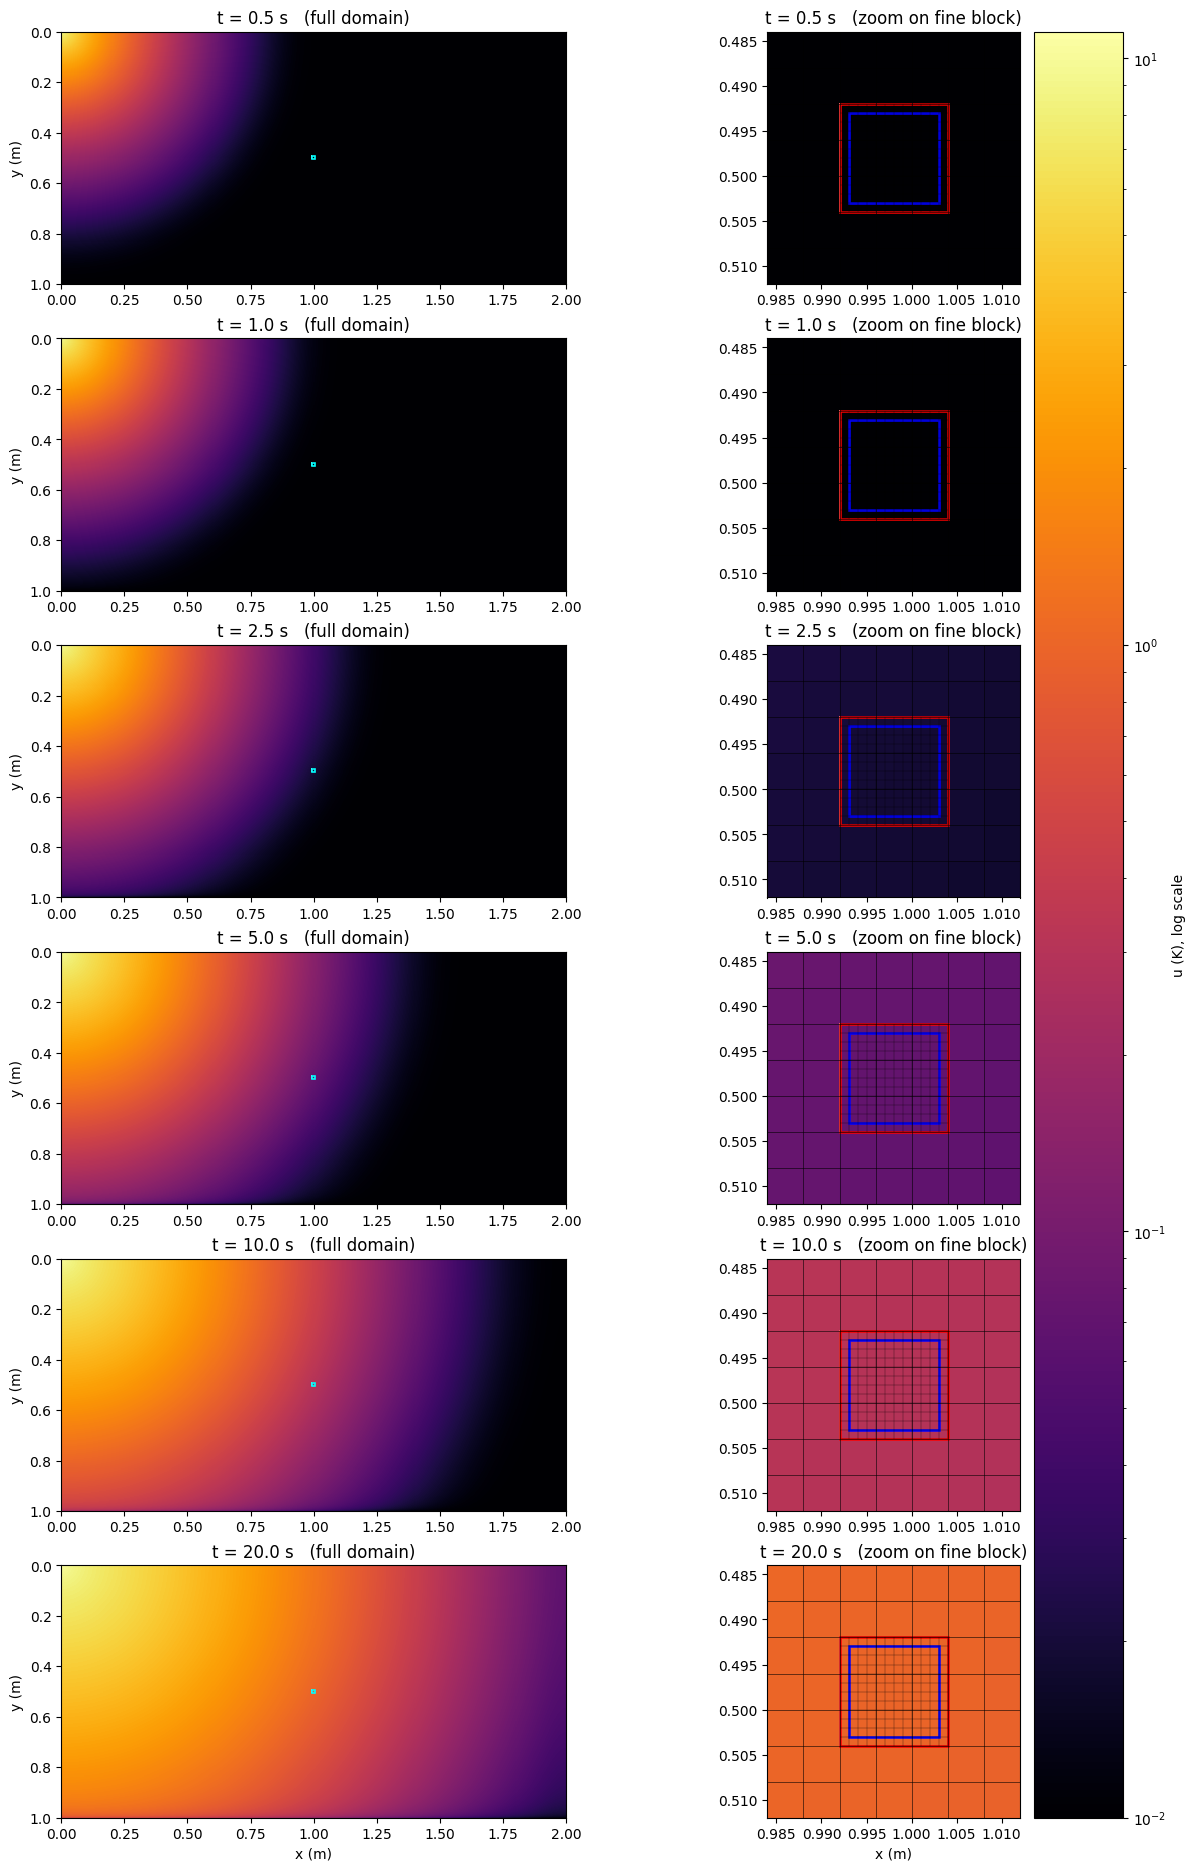

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Rectangle

# ---------- settings ----------
t_want = [0.5, 1, 2.5, 5, 10, 20]      # seconds (multiples of dt)
scale  = "log"                         # "log" or "linear"
vmin   = u_fixed                       # lower colour limit (K)
vmax   = None                          # None -> maximum over the chosen frames

frames   = [min(int(round(t / dt)), N_t_steps - 1) for t in t_want]
t_actual = [f * dt for f in frames]
print("frame indices:", frames, " times (s):", t_actual)

# ---------- geometry ----------
fx0, fy0 = fine_start_i * dx_coarse, fine_start_j * dy_coarse
fine_w, fine_h = coarse_replaced_x * dx_coarse, coarse_replaced_y * dy_coarse
fx1, fy1 = fx0 + fine_w, fy0 + fine_h
qx0, qy0 = fx0 + dx_fine, fy0 + dy_fine
qw, qh = Nx_quartz * dx_fine, Ny_quartz * dy_fine

pad = 2
i0, i1 = max(fine_start_i - pad, 0), min(fine_end_i + pad + 1, Nx_coarse)
j0, j1 = max(fine_start_j - pad, 0), min(fine_end_j + pad + 1, Ny_coarse)
zx = (i0 * dx_coarse, i1 * dx_coarse)
zy = (j1 * dy_coarse, j0 * dy_coarse)

coarse_in_fine = np.zeros((Ny_coarse, Nx_coarse), dtype=bool)
coarse_in_fine[fine_start_j:fine_end_j + 1, fine_start_i:fine_end_i + 1] = True

def fields(f):
    raw_c = u[:total_coarse, f].reshape(Ny_coarse, Nx_coarse)
    raw_f = u[total_coarse:, f].reshape(Ny_fine, Nx_fine)
    uc = np.ma.masked_where(coarse_in_fine | ~np.isfinite(raw_c), raw_c)
    uf = np.ma.masked_where(~np.isfinite(raw_f), raw_f)
    return uc, uf

cmap = plt.get_cmap("inferno").copy()
cmap.set_bad("lightgrey")

# ---------- ONE norm for every panel ----------
if vmax is None:
    vmax = max(np.nanmax(u[:, f]) for f in frames)
if scale == "log":
    norm = LogNorm(vmin=vmin, vmax=vmax, clip=True)
else:
    norm = Normalize(vmin=vmin, vmax=vmax, clip=True)
print(f"colour range: {vmin:.3g} to {vmax:.3g} K ({scale})")

# ---------- plot ----------
fig, axes = plt.subplots(len(frames), 2, figsize=(14, 3.1 * len(frames)),
                         gridspec_kw={"width_ratios": [2, 1.1]},
                         constrained_layout=True)
axes = np.atleast_2d(axes)

for row, (f, t) in enumerate(zip(frames, t_actual)):
    uc, uf = fields(f)

    # ----- full domain (left) -----
    ax = axes[row, 0]
    im = ax.imshow(uc, extent=[0, domain_w, domain_l, 0], cmap=cmap, norm=norm,
                   interpolation="nearest")
    ax.imshow(uf, extent=[fx0, fx1, fy1, fy0], cmap=cmap, norm=norm,
              interpolation="nearest")
    ax.add_patch(Rectangle((fx0, fy0), fine_w, fine_h, fill=False, edgecolor="cyan", lw=1.2))
    ax.set_xlim(0, domain_w); ax.set_ylim(domain_l, 0)
    ax.set_title(f"t = {t:.1f} s   (full domain)")
    ax.set_ylabel("y (m)")
    if row == len(frames) - 1:
        ax.set_xlabel("x (m)")

    # ----- zoom on fine block (right) -----
    az = axes[row, 1]
    az.imshow(uc, extent=[0, domain_w, domain_l, 0], cmap=cmap, norm=norm,
              interpolation="nearest")
    az.imshow(uf, extent=[fx0, fx1, fy1, fy0], cmap=cmap, norm=norm,
              interpolation="nearest")

    az.vlines(np.arange(i0, i1 + 1) * dx_coarse, zy[1], zy[0], colors="k", lw=0.4)
    az.hlines(np.arange(j0, j1 + 1) * dy_coarse, zx[0], zx[1], colors="k", lw=0.4)
    az.vlines(fx0 + np.arange(Nx_fine + 1) * dx_fine, fy0, fy1, colors="k", lw=0.2)
    az.hlines(fy0 + np.arange(Ny_fine + 1) * dy_fine, fx0, fx1, colors="k", lw=0.2)

    az.add_patch(Rectangle((fx0, fy0), fine_w, fine_h, fill=False, edgecolor="red", lw=1.8))
    az.add_patch(Rectangle((qx0, qy0), qw, qh, fill=False, edgecolor="blue", lw=1.8))
    az.set_xlim(*zx); az.set_ylim(*zy)
    az.set_title(f"t = {t:.1f} s   (zoom on fine block)")
    if row == len(frames) - 1:
        az.set_xlabel("x (m)")

fig.colorbar(im, ax=axes.ravel().tolist(), label=f"u (K), {scale} scale", pad=0.01)
plt.show()